In [18]:
#adata = sc.read_h5ad('./tnbc.h5ad.gz')
adata = sc.read("./visiumHD scniche.h5ad")## requires a non-normalized adata object


In [4]:
#https://github.com/ZJUFanLab/scNiche/blob/main/tutorial/tutorial_tnbc.ipynb
import scniche as sn
import numpy as np
import scanpy as sc
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scniche.pl import *
import warnings
import anndata
warnings.filterwarnings('ignore')

print("Last run with scNiche version:", sn.__version__)

# set seed
sn.pp.set_seed()

Last run with scNiche version: 1.1.0


In [7]:
adata

AnnData object with n_obs × n_vars = 122372 × 19059
    obs: 'orig.ident', 'nCount_Spatial.Polygons', 'nFeature_Spatial.Polygons', 'group', 'nCount_Spatial', 'nFeature_Spatial', 'Cell_Anno', 'Type', 'niche', 'Celltype', 'celltype', 'barcode'
    obsm: 'X_pca', 'X_spatial', 'X_umap'

In [13]:
#adata2=adata[adata.obs['banksy_niche'] == 'niche_3']
#adata2.obs_names = adata2.obs_names.astype(str)
#adata1 = adata2[adata2.obs['group'].isin(['10w_1', '10w_2'])].copy()

custom_order = [
    'EC', 
    'T cell',
    'LAMs','Res Mac','Inf Mac','DCs','Mono','Cycling Myeloid',
    'SC',
    'vSMCs',
    'FBs C1', 'FBs C2', 'FBs C3', 'FBs C4', 'FBs C5', 'FBs C6', 'FBs C7','FBs C8'
]
colors_FB=('#d51f26',
           '#0F7240',#T
           '#FCCC3A','#d5a339','#f3758a','#C67052','#F49E47','#C0937E',#Mac
            "#5d2b84", #SC 
           "#9d9ac6", #SMC
            "#b1ddcc",  "#00a7fa","#92B2D8",'#C9E1AF',
            "#bbe379", '#b9e6fb', '#7AA15E',"#31aaaa" #FMC
          )


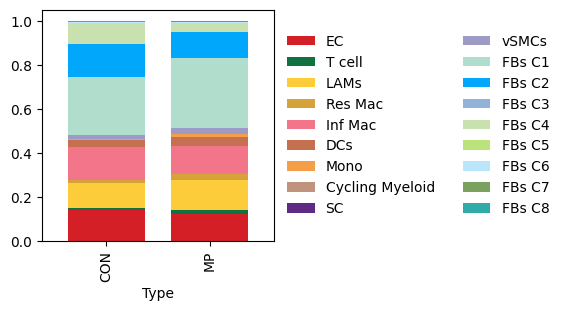

In [14]:

adata.obs['Celltype'] = pd.Categorical(
    adata.obs['Celltype'], 
    categories=custom_order,  # define levels in this order
    ordered=True
)
kwargs = {'figsize': (3, 3)}
sn.pl.stacked_barplot(adata, x_axis='Type', y_axis='Celltype', mode='proportion', 
                      palette=colors_FB, kwargs=kwargs)
plt.savefig('./cellratio.pdf', bbox_inches='tight',   dpi=500 )

#sn.pl.stacked_barplot(adata1, x_axis='banksy_niche', y_axis='Type', mode='proportion',
#                      palette=['#426cb5', '#bababa', '#ff7700'], kwargs=kwargs)

<Axes: title={'center': 'banksy_niche'}, xlabel='spatial1', ylabel='spatial2'>

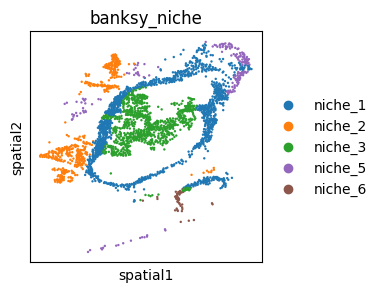

In [35]:
plt.rcParams["figure.figsize"] = (3, 3)
sc.pl.embedding(adata[adata.obs['group'] == '15w_2'], basis="spatial", 
                color=['banksy_niche',],s=12, show=False)

Calculating the enrichment of each cluster (Celltype) in group (niche)...


Cluster: vSMCs: 100%|████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00, 192.78it/s]


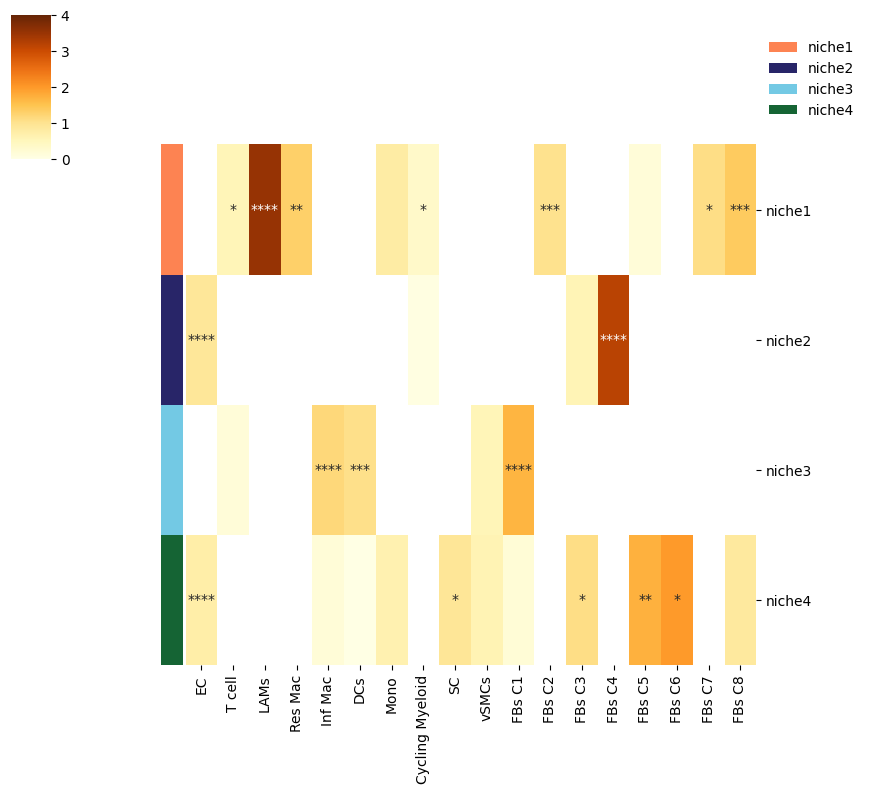

In [21]:
adata.obs['Celltype'] = adata.obs['Celltype'].astype(str)

# cell type enrichment
sn.al.enrichment(adata, id_key='Celltype', 
                 val_key='niche',
                 library_key='group')
colors_niche=('#FD8352', '#282568','#73c9e4',  '#156434'
             )
# plot
kwargs = {'figsize': (8, 8), 'vmax': 4, 'cmap': 'YlOrBr', 'linewidths': 0, 'linecolor': 'white', }
col_order = [ 'EC', 
    'T cell',
    'LAMs','Res Mac','Inf Mac','DCs','Mono','Cycling Myeloid',
    'SC',
    'vSMCs',
    'FBs C1', 'FBs C2', 'FBs C3', 'FBs C4', 'FBs C5', 'FBs C6', 'FBs C7','FBs C8']
row_order = ['niche1', 'niche2', 'niche3', 'niche4' ]

colors1 = colors_niche## niche color palette
categories1 = adata.obs['niche'].cat.categories
palette_use = [colors1[list(categories1).index(cat)] for cat in row_order]

sn.pl.enrichment_heatmap(adata=adata, id_key='Celltype', val_key='niche', binarized=False, show_pval=True,
                     col_order=col_order, row_order=row_order, anno_key=None, anno_palette=palette_use,
                         kwargs=kwargs)
plt.savefig( './niche_enrichment_heatmap.pdf', bbox_inches='tight', dpi=500 )